<a href="https://colab.research.google.com/github/elisabethandriivna/Portfolio/blob/main/Lab1_Kaprelova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Passengerid   Age     Fare  Sex  sibsp  zero  zero.1  zero.2  zero.3  \
0            1  22.0   7.2500    0      1     0       0       0       0   
1            2  38.0  71.2833    1      1     0       0       0       0   
2            3  26.0   7.9250    1      0     0       0       0       0   
3            4  35.0  53.1000    1      1     0       0       0       0   
4            5  35.0   8.0500    0      0     0       0       0       0   

   zero.4  ...  zero.12  zero.13  zero.14  Pclass  zero.15  zero.16  Embarked  \
0       0  ...        0        0        0       3        0        0       2.0   
1       0  ...        0        0        0       1        0        0       0.0   
2       0  ...        0        0        0       3        0        0       2.0   
3       0  ...        0        0        0       1        0        0       2.0   
4       0  ...        0        0        0       3        0        0       2.0   

   zero.17  zero.18  2urvived  
0        0        0         0 

/tmp/ipykernel_470/3389107153.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df.groupby(["Sex", "Age_group", "2urvived"]).size().reset_index(name="Count")
/tmp/ipykernel_470/3389107153.py:30: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = grouped.pivot_table(index=["Sex", "Age_group"], columns="2urvived", values="Count", fill_value=0)


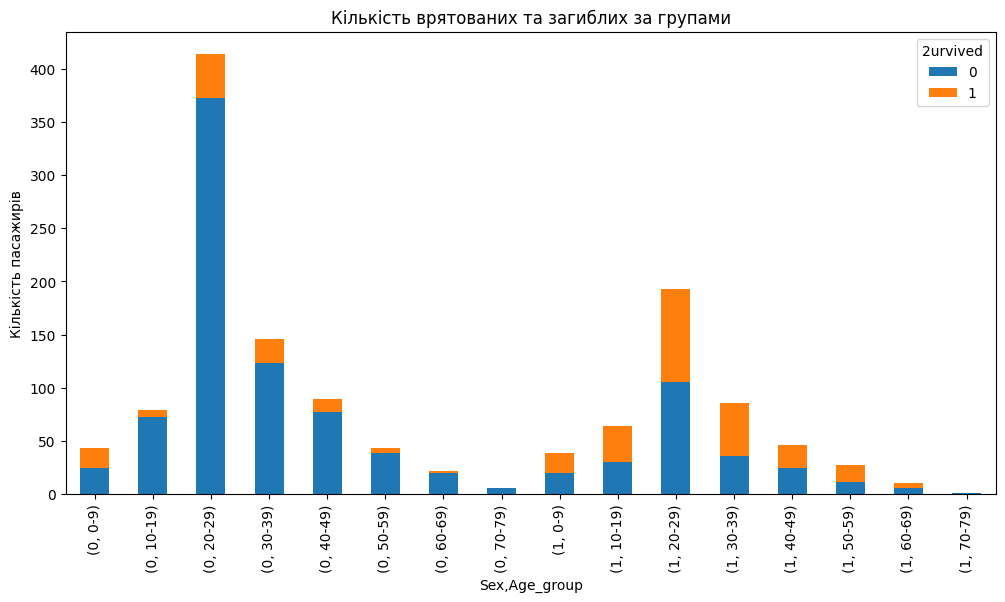

Кількість врятованих та відсоток для кожної групи:
2urvived       Died  Survived  Total  Survival_rate
Sex Age_group                                      
0   0-9          24        19     43      44.186047
    10-19        72         7     79       8.860759
    20-29       373        41    414       9.903382
    30-39       123        23    146      15.753425
    40-49        77        12     89      13.483146
    50-59        39         4     43       9.302326
    60-69        20         2     22       9.090909
    70-79         6         0      6       0.000000
1   0-9          20        19     39      48.717949
    10-19        30        34     64      53.125000
    20-29       105        88    193      45.595855
    30-39        36        50     86      58.139535
    40-49        24        22     46      47.826087
    50-59        11        16     27      59.259259
    60-69         6         4     10      40.000000
    70-79         1         0      1       0.000000

Група з найб

/tmp/ipykernel_470/3389107153.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pivot = df.groupby(["Sex", "Age_group", "2urvived"]).size().unstack(fill_value=0)


In [3]:
# -*- coding: utf-8 -*-
"""Lab1_Kaprelova.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1i9jK2vJHZIFPJGF4N6KMQYXO2gO3piZJ
"""

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("/content/train_and_test2.csv")

print(df.head())       # перші 5 рядків
print(df.columns)
print(df.info())       # типи даних і кількість пропусків
print(df.describe())   # статистика по числових полях
print(df.shape)        # розмірність (рядки, колонки)
print(df.dtypes)       # типи колонок

bins = range(0, 90, 10)  # від 0 до 80 по 10 років
labels = [f"{i}-{i+9}" for i in bins[:-1]]

df["Age_group"] = pd.cut(df["Age"], bins=bins, labels=labels, right=False)
grouped = df.groupby(["Sex", "Age_group", "2urvived"]).size().reset_index(name="Count")
print(grouped)

pivot = grouped.pivot_table(index=["Sex", "Age_group"], columns="2urvived", values="Count", fill_value=0)
pivot.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Кількість врятованих та загиблих за групами")
plt.ylabel("Кількість пасажирів")
plt.show()


# Робимо зведену таблицю: кількість загиблих (0) і врятованих (1)
pivot = df.groupby(["Sex", "Age_group", "2urvived"]).size().unstack(fill_value=0)

# Перейменуємо колонки для зручності
pivot = pivot.rename(columns={0: "Died", 1: "Survived"})

# Рахуємо загальну кількість і відсоток врятованих
pivot["Total"] = pivot["Died"] + pivot["Survived"]
pivot["Survival_rate"] = pivot["Survived"] / pivot["Total"] * 100

print("Кількість врятованих та відсоток для кожної групи:")
print(pivot)

# Група з максимальною кількістю врятованих
max_count_group = pivot["Survived"].idxmax()
print("\nГрупа з найбільшою кількістю врятованих:", max_count_group,
      "| Кількість:", pivot.loc[max_count_group, "Survived"])

# Група з найбільшим відсотком виживання
max_rate_group = pivot["Survival_rate"].idxmax()
print("Група з найбільшим відсотком врятованих:", max_rate_group,
      "| Виживання:", f"{pivot.loc[max_rate_group, 'Survival_rate']:.2f}%")
